# Demo

Do imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *

Load data from a flight in which the drone took off, moved in a square, and landed.

In [ ]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('mocap_test.json')

Resample drone data.

In [3]:
data_drone = resample_data_drone(raw_data_drone, t_min_offset=0.1, t_max_offset=0.)

t = data_drone['time']
x_drone = data_drone['stateEstimate.x']
y_drone = data_drone['stateEstimate.y']
z_drone = data_drone['stateEstimate.z']
psi_drone = np.deg2rad(data_drone['stateEstimate.yaw'])
theta_drone = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi_drone = np.deg2rad(data_drone['stateEstimate.roll'])

Resample mocap data (with an optimal time shift and with coordinate transformation).

In [ ]:
data_mocap = sync_data_mocap(
    raw_data_mocap,
    t,
    z_drone,
    do_transform=True,      # <-- whether to align mocap data in space
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)




x_mocap = data_mocap['x']
y_mocap = data_mocap['y']
z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

Plot $x, y$ data.

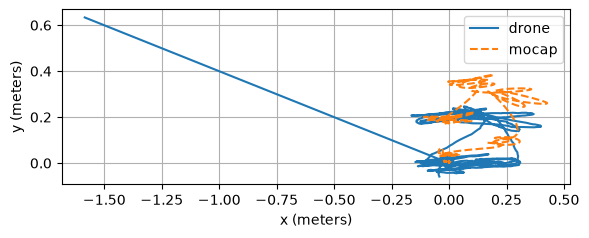

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), tight_layout=True)
ax.plot(x_drone, y_drone, label='drone')
ax.plot(x_mocap, y_mocap, '--', label='mocap')
ax.legend()
ax.grid()
ax.set_aspect('equal')
ax.set_xlabel('x (meters)')
ax.set_ylabel('y (meters)')
plt.show()

Plot all data.

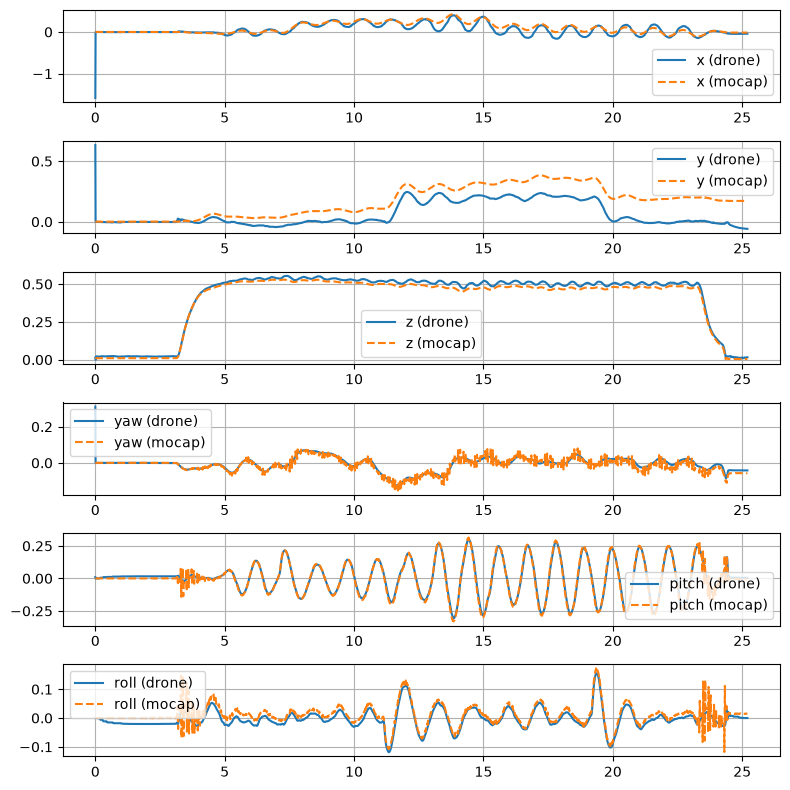

In [ ]:
fig, (ax_x, ax_y, ax_z, ax_psi, ax_theta, ax_phi) = plt.subplots(6, 1, figsize=(8, 8), tight_layout=True)

ax_x.plot(t, x_pur, label='x (pursuer)')
ax_x.plot(t, x_run, '--', label='x (runner)')
ax_x.legend()
ax_x.grid()

ax_y.plot(t, y_pur, label='y (pursuer)')
ax_y.plot(t, y_run, '--', label='y (runner)')
ax_y.legend()
ax_y.grid()

ax_z.plot(t, z_pur, label='z (pursuer)')
ax_z.plot(t, z_run, '--', label='z (runner)')
ax_z.legend()
ax_z.grid()

ax_psi.plot(t, psi_pur, label='yaw (pursuer)')
ax_psi.plot(t, psi_run, '--', label='yaw (runner)')
ax_psi.legend()
ax_psi.grid()

ax_theta.plot(t, theta_pur, label='pitch (pursuer)')
ax_theta.plot(t, theta_run, '--', label='pitch (runner)')
ax_theta.legend()
ax_theta.grid()

ax_phi.plot(t, phi_pur, label='roll (pursuer)')
ax_phi.plot(t, phi_run, '--', label='roll (runner)')
ax_phi.legend()
ax_phi.grid()

plt.show()

### Reflection

Review the reflection you put in your Lab 1 notebook. **Modify the text in this cell** to answer the following three questions with at least one sentence each:
* What was your biggest struggle this week? Was it the same or different from last week?

The largest struggle was keeping straight which frames each variable was related to and how they related to each other.

* What was the most important thing you learned this week?

getting more comfortable working with the varying frames and transforming between them.

* How does what you learned this week relate to what you learned last week?

The use of the mocap provided a separtate set of data to validate position for the same flight path used in lab 01 